# Comparación de Yahoo Finance y Financial Modeling Prep

Este notebook comprueba que **ambas APIs devuelven objetos con la misma estructura**, muestra precios y estados financieros y compara los ejercicios disponibles. **No presupone que las cifras de las dos fuentes sean idénticas**: pueden variar por ajustes, divisas o criterios contables.

**Preparación:** guarda este notebook en tu carpeta `Pruebas`, junto a `YahooFinanceAPI.py`, `fmp_api.py`, tus clases y el archivo `.env`. Ejecuta las celdas en orden. Se necesitan acceso a Internet y una clave FMP con acceso a los endpoints solicitados.

> Nota: los archivos disponibles aquí corresponden a una versión anterior de algunas clases; este notebook está preparado para tu versión actual descrita en la conversación (con `PriceSeries` y `FMPAPI`). No se han ejecutado peticiones reales a las APIs.

## 1. Importaciones y clave de FMP

In [1]:
# Si faltan dependencias, ejecuta esta línea una sola vez:
# %pip install pandas numpy yfinance requests python-dotenv

import os
from pathlib import Path
from dataclasses import fields, is_dataclass
import pandas as pd
from IPython.display import display
from dotenv import load_dotenv

load_dotenv(Path.cwd() / ".env")
api_key = os.getenv("FMP_API_KEY")
assert api_key, "Falta FMP_API_KEY en el archivo .env"
print("Clave FMP cargada correctamente (no se muestra).")

Clave FMP cargada correctamente (no se muestra).


## 2. Crear las dos APIs y descargar la misma empresa

In [2]:
# Si tu proyecto utiliza imports relativos (from .stock import Stock),
# ejecuta el notebook desde la carpeta PADRE e importa mediante el nombre del paquete.
from YahooFinanceAPI import YahooFinanceAPI
from fmp_api import FMPAPI

yahoo_api = YahooFinanceAPI()
fmp_api = FMPAPI(api_key=api_key)

ticker = "AAPL"
stock_yahoo = yahoo_api.get_stock(ticker, period="5y", interval="1d")
stock_fmp = fmp_api.get_stock(ticker, period="5y", interval="1d")

print("Yahoo:", stock_yahoo.company.name)
print("FMP:", stock_fmp.company.name)

Income statement for AAPL requires a paid FMP subscription
Balance sheet for AAPL requires a paid FMP subscription
Cash flow for AAPL requires a paid FMP subscription
Yahoo: Apple Inc.
FMP: Apple Inc.


## 3. Comprobar tipos y estructura

In [3]:
print("Tipos de Stock:", type(stock_yahoo).__name__, type(stock_fmp).__name__)
assert type(stock_yahoo) is type(stock_fmp), "Las APIs no devuelven la misma clase Stock"

for label, a, b in [
    ("Stock", stock_yahoo, stock_fmp),
    ("PriceSeries", stock_yahoo.price, stock_fmp.price),
    ("Company", stock_yahoo.company, stock_fmp.company),
    ("Fundamentals", stock_yahoo.company.fundamentals, stock_fmp.company.fundamentals),
]:
    assert type(a) is type(b), f"Distinto tipo en {label}"
    print(f"{label}: OK ({type(a).__name__})")

for name in ["income_statements", "balance_sheets", "cash_flows"]:
    a = getattr(stock_yahoo.company.fundamentals, name)
    b = getattr(stock_fmp.company.fundamentals, name)
    assert type(a) is type(b), f"Distinto tipo en {name}"
    print(f"{name}: OK ({type(a).__name__})")

if is_dataclass(stock_yahoo):
    print("Atributos de Stock:", [f.name for f in fields(stock_yahoo)])

Tipos de Stock: Stock Stock
Stock: OK (Stock)
PriceSeries: OK (PriceSeries)
Company: OK (Company)
Fundamentals: OK (Fundamentals)
income_statements: OK (IncomeStatementHistory)
balance_sheets: OK (BalanceSheetHistory)
cash_flows: OK (CashFlowHistory)
Atributos de Stock: ['ticker', 'price', 'company']


## 4. Comprobar precios y verlos en tablas

La versión actual de `PriceSeries` utiliza atributos separados (`date`, `open`, `high`, `low`, `close`, `volume`).

In [4]:
for nombre, stock in [("Yahoo", stock_yahoo), ("FMP", stock_fmp)]:
    p = stock.price
    print(f"{nombre}")
    for atributo in ["date", "open", "high", "low", "close", "volume"]:
        assert hasattr(p, atributo), f"Falta {atributo} en {nombre}"
    print("Observaciones:", len(p.close))
    print("Último cierre:", p.close.iloc[-1])
    if hasattr(p, "to_dataframe"):
        display(p.to_dataframe().tail())
    else:
        display(pd.DataFrame({
            "Open": p.open.to_numpy(), "High": p.high.to_numpy(),
            "Low": p.low.to_numpy(), "Close": p.close.to_numpy(),
            "Volume": p.volume.to_numpy()
        }, index=p.date).tail())

Yahoo
Observaciones: 1255
Último cierre: 338.7049865722656


,Open,High,Low,Close,Volume
Date,,,,,
2026-10-27 00:00:00-04:00,343.170013,347.779999,342.390015,347.100006,39984400
2026-10-28 00:00:00-04:00,346.920013,347.179993,343.519989,343.829987,35714300
2026-10-29 00:00:00-04:00,348.000000,351.429993,347.299988,348.910004,42582100
2026-10-30 00:00:00-04:00,346.720001,349.190002,334.350006,344.630005,67797500
2026-11-02 00:00:00-05:00,342.670013,343.779999,336.520599,338.704987,22267836


FMP
Observaciones: 1257
Último cierre: 338.285


,Open,High,Low,Close,Volume
date,,,,,
2026-10-27,343.17,347.78,342.390,347.100,39984400
2026-10-28,346.92,347.18,343.520,343.830,35714331
2026-10-29,348.00,351.43,347.300,348.910,42582126
2026-10-30,346.72,349.19,334.350,344.630,67842804
2026-11-02,342.67,343.78,336.575,338.285,22191530


## 5. Comparar los cierres en las mismas fechas

**Atención:** Yahoo usa `auto_adjust=True`; FMP puede aplicar otro criterio de ajuste. Diferencias en el cierre no implican necesariamente un error.

Fechas comunes: 1255


,Yahoo,FMP,Diferencia,Diferencia_%
2026-10-20,339.500000,339.500,0.000000,0.000000e+00
2026-10-21,343.989990,343.990,-0.000010,-2.838927e-06
2026-10-22,348.220001,348.220,0.000001,3.505551e-07
2026-10-23,347.730011,347.730,0.000011,3.159442e-06
2026-10-26,343.910004,343.910,0.000004,1.064845e-06
2026-10-27,347.100006,347.100,0.000006,1.758431e-06
2026-10-28,343.829987,343.830,-0.000013,-3.905341e-06
2026-10-29,348.910004,348.910,0.000004,1.049586e-06
2026-10-30,344.630005,344.630,0.000005,1.416827e-06
2026-11-02,338.704987,338.285,0.419987,1.241517e-01


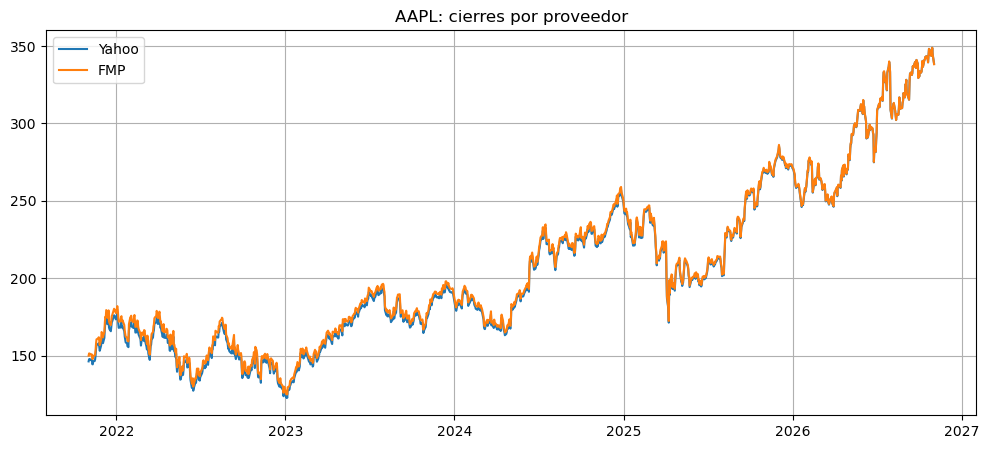

In [5]:
yahoo_close = stock_yahoo.price.close.copy()
fmp_close = stock_fmp.price.close.copy()

yahoo_close.index = yahoo_close.index.date
fmp_close.index = fmp_close.index.date

cierres = pd.concat([
    yahoo_close.rename("Yahoo"),
    fmp_close.rename("FMP")
], axis=1).dropna()

cierres["Diferencia"] = cierres["Yahoo"] - cierres["FMP"]
cierres["Diferencia_%"] = (cierres["Diferencia"] / cierres["FMP"]) * 100

print("Fechas comunes:", len(cierres))

display(cierres.tail(10))

if not cierres.empty:
    cierres[["Yahoo", "FMP"]].plot(
        figsize=(12, 5),
        title=f"{ticker}: cierres por proveedor",
        grid=True
    )

## 6. Comparar los estados financieros disponibles

In [6]:
resultados = []
for nombre in ["income_statements", "balance_sheets", "cash_flows"]:
    a = getattr(stock_yahoo.company.fundamentals, nombre)
    b = getattr(stock_fmp.company.fundamentals, nombre)
    assert hasattr(a, "statements") and hasattr(b, "statements"), "Se esperaba el atributo statements"
    resultados.append({
        "Estado": nombre,
        "Ejercicios Yahoo": len(a.statements),
        "Ejercicios FMP": len(b.statements),
        "Fechas Yahoo": sorted(str(s.date) for s in a.statements),
        "Fechas FMP": sorted(str(s.date) for s in b.statements),
    })
display(pd.DataFrame(resultados))

,Estado,Ejercicios Yahoo,Ejercicios FMP,Fechas Yahoo,Fechas FMP
0,income_statements,4,0,"[2022-09-30, 2023-09-30, 2024-09-30, 2025-09-30]",[]
1,balance_sheets,4,0,"[2022-09-30, 2023-09-30, 2024-09-30, 2025-09-30]",[]
2,cash_flows,4,0,"[2022-09-30, 2023-09-30, 2024-09-30, 2025-09-30]",[]


## 7. Comprobar que cada estado financiero tiene los mismos atributos

In [7]:
for nombre in ["income_statements", "balance_sheets", "cash_flows"]:
    a = getattr(stock_yahoo.company.fundamentals, nombre).statements
    b = getattr(stock_fmp.company.fundamentals, nombre).statements
    if a and b:
        assert type(a[0]) is type(b[0]), f"Clases diferentes en {nombre}"
        atributos_a = [f.name for f in fields(a[0])]
        atributos_b = [f.name for f in fields(b[0])]
        assert atributos_a == atributos_b
        print(f"{nombre}: OK → {len(atributos_a)} atributos; clase {type(a[0]).__name__}")
    else:
        print(f"{nombre}: sin datos suficientes en alguna API para comparar")

income_statements: sin datos suficientes en alguna API para comparar
balance_sheets: sin datos suficientes en alguna API para comparar
cash_flows: sin datos suficientes en alguna API para comparar


## 8. `get_by_year()` y `to_dataframe()` (si ya los añadiste)

In [8]:
for nombre, stock in [("Yahoo", stock_yahoo), ("FMP", stock_fmp)]:

    print(f"===== {nombre} =====")

    history = stock.company.fundamentals.income_statements

    df = history.to_dataframe()

    if df.empty:
        print("No hay estados financieros disponibles")

    else:
        display(df.iloc[:8, :5])

        year = df.columns[0].year

        print(f"get_by_year({year}):")
        print(history.get_by_year(year))

===== Yahoo =====


date,2025-09-30,2024-09-30,2023-09-30,2022-09-30
total_revenue,4.161610e+11,3.910350e+11,3.832850e+11,3.943280e+11
cost_revenue,2.209600e+11,2.103520e+11,2.141370e+11,2.235460e+11
gross_profit,1.952010e+11,1.806830e+11,1.691480e+11,1.707820e+11
operating_expense,6.215100e+10,5.746700e+10,5.484700e+10,5.134500e+10
operating_income,1.330500e+11,1.232160e+11,1.143010e+11,1.194370e+11
interest_expense,NaN,NaN,3.933000e+09,2.931000e+09
pretax_income,1.327290e+11,1.234850e+11,1.137360e+11,1.191030e+11
tax_provision,2.071900e+10,2.974900e+10,1.674100e+10,1.930000e+10


get_by_year(2025):
IncomeStatement(date=datetime.date(2025, 9, 30), total_revenue=416161000000.0, cost_revenue=220960000000.0, gross_profit=195201000000.0, operating_expense=62151000000.0, operating_income=133050000000.0, interest_expense=nan, pretax_income=132729000000.0, tax_provision=20719000000.0, net_income=112010000000.0)
===== FMP =====
No hay estados financieros disponibles


## 9. Ejecutar los análisis de `Fundamentals`

Se ejecuta cada análisis por separado para que puedas localizar errores en los cálculos si falta algún dato contable.

In [10]:
for nombre, stock in [("Yahoo", stock_yahoo), ("FMP", stock_fmp)]:
    print(f"===== ANÁLISIS {nombre} =====")
    fundamentals = stock.company.fundamentals
    for etiqueta, metodo in [
        ("Income Statement", fundamentals.analyze_income_statement),
        ("Balance Sheet", fundamentals.analyze_balance_sheet),
        ("Cash Flow", fundamentals.analyze_cash_flow),
    ]:
        print(etiqueta)
        # Si hay divisiones por cero o datos NaN, revisa la definición de los campos.
        df = metodo()
        assert isinstance(df, pd.DataFrame)
        display(df.head())

===== ANÁLISIS Yahoo =====
Income Statement


,2022,2023,2024,2025
Gross margin percentage,43.309631,44.13113,46.20635,46.905164
Operating margin percentage,30.288744,29.821412,31.510223,31.9708
Operating expense to revenue,13.020886,14.309717,14.696127,14.934364
Consistency (Gross profit - operating expenses = operating income),True,True,True,True
Revenue growth,NaN,-2.800461,2.021994,6.425512


Balance Sheet


,2022,2023,2024,2025
Debt-to-equity ratio,2.614462,1.787533,1.872327,1.33803
Current assets weight (%),38.384998,40.718356,41.916543,41.186
Inventory weight (%),1.402106,1.795606,1.996274,1.591689
Net PPE weight (%),11.939448,12.398499,12.515754,13.872025
Intangible assets weight (%),NaN,NaN,NaN,NaN


Cash Flow


,2022,2023,2024,2025
Consistency (CFO + CFI + CFF = Net cash change),True,True,True,True
Free cash flow (FCF),111443000000.0,99584000000.0,108807000000.0,98767000000.0
CAPEX/DA ratio,0.964337,0.951385,0.825426,1.086938
CAPEX/CFO ratio,0.087662,0.099138,0.079887,0.114054
Dividend coverage,7.50913,6.627887,7.142379,6.404708


... (2 outputs left out)

Balance Sheet


""


Cash Flow


""


## 10. Comparar una partida contable por ejercicio

La comparación se hace por **año fiscal** y solo para años presentes en ambas fuentes. Antes de interpretar diferencias, verifica moneda, definición de la partida y fecha de cierre.

In [11]:
filas = []
for nombre, atributo in [
    ("income_statements", "total_revenue"),
    ("income_statements", "net_income"),
    ("balance_sheets", "total_assets"),
    ("cash_flows", "operating_cash_flow"),
]:
    h_y = getattr(stock_yahoo.company.fundamentals, nombre).statements
    h_f = getattr(stock_fmp.company.fundamentals, nombre).statements
    por_anio_y = {s.date.year: s for s in h_y}
    por_anio_f = {s.date.year: s for s in h_f}
    for year in sorted(set(por_anio_y) & set(por_anio_f)):
        y = getattr(por_anio_y[year], atributo)
        f = getattr(por_anio_f[year], atributo)
        filas.append({"Estado": nombre, "Partida": atributo, "Año": year,
                      "Yahoo": y, "FMP": f, "Diferencia": y - f})
comparacion = pd.DataFrame(filas)
if comparacion.empty:
    print("No hay años fiscales comunes para comparar")
else:
    display(comparacion)

No hay años fiscales comunes para comparar


## Interpretación

- **Mismo tipo de objeto y atributos:** demuestra que tus adaptadores ofrecen una interfaz común.
- **Diferencias en precios:** comprueba primero el ajuste por dividendos/splits.
- **Diferencias en estados financieros:** comprueba moneda, fecha fiscal, signos y equivalencia contable de los campos.
- **Faltan datos en FMP:** puede depender de tu plan de API o de la cobertura del ticker.

**Importante:** que dos objetos sean comparables estructuralmente **no garantiza** que sus cifras sean económicamente equivalentes. Esa segunda comprobación requiere revisar el mapeo de campos de ambas APIs.